In [1]:
from code_CTICU.MLfcn import extval,exteval_saveprobs
from code_CTICU.MLfcn import val,val_saveprobs
clfname = 'topn_features'

import pandas as pd
savepath = 'results/postsurgery_model'
import pickle
with open(savepath+'/topn_features.pkl','rb') as file:
    clfs = pickle.load(file)

Xtest = pd.read_csv('data/processed/internal_Xtest.csv',index_col=0)
Ytest = pd.read_csv('data/processed/internal_Ytest.csv',index_col=0)

Xpros = pd.read_csv('data/processed/temporal_X.csv',index_col=0)
Ypros = pd.read_csv('data/processed/temporal_Y.csv',index_col=0)

X_bwh = pd.read_csv('data/processed/external_bwh_X.csv',index_col=0)
X_bwh['Surgery Time'] = X_bwh['Surgery Time']/60

Y_bwh = pd.read_csv('data/processed/external_bwh_Y.csv',index_col=0)
Y_bwh = Y_bwh.iloc[:,1:]

Ytest = Ytest.reset_index(drop=True)
Ypros = Ypros.reset_index(drop=True)
Y_bwh = Y_bwh.reset_index(drop=True)

In [2]:
probs_retro = pd.read_csv('results/postsurgery_model/probs_topn_features_internal.csv',index_col=0)
probs_pros = pd.read_csv('results/postsurgery_model/probs_topn_features_temporal.csv',index_col=0)
probs_bwh = pd.read_csv('results/postsurgery_model/probs_topn_features_external_bwh.csv',index_col=0)

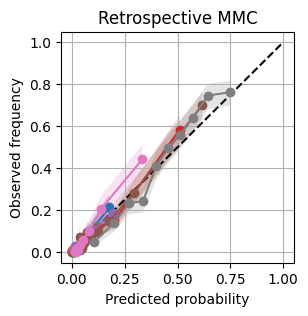

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

# probs_retro: predicted probabilities (rows = samples, cols = outcomes)
# Ytest: true labels (same shape, 0/1)

n_bins = 10

plt.figure(figsize=(3, 3))

# perfect calibration line
plt.plot([0, 1], [0, 1], "--", color="black", label="Perfect calibration")

for col in probs_retro.columns:
    df = pd.DataFrame({
        "y_prob": probs_retro[col],
        "y_true": Ytest[col]
    }).dropna()

    # Quantile-based bins
    df["bin"] = pd.qcut(df["y_prob"], q=n_bins, duplicates="drop")

    cal = (
        df.groupby("bin", observed=False)
          .agg(
              mean_pred=("y_prob", "mean"),
              obs_rate=("y_true", "mean"),
              n=("y_true", "size"),
              events=("y_true", "sum")
          )
          .dropna()
          .reset_index(drop=True)
    )

    # Wilson 95% CI for observed event rate in each bin
    ci_low, ci_upp = proportion_confint(
        count=cal["events"],
        nobs=cal["n"],
        alpha=0.05,
        method="wilson"
    )

    cal["ci_low"] = ci_low
    cal["ci_upp"] = ci_upp

    # line
    plt.plot(
        cal["mean_pred"],
        cal["obs_rate"],
        marker="o",
        label=col
    )

    # ribbon
    plt.fill_between(
        cal["mean_pred"],
        cal["ci_low"],
        cal["ci_upp"],
        alpha=0.2
    )

plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("Retrospective MMC")
# plt.legend()
plt.grid(True)
plt.show()


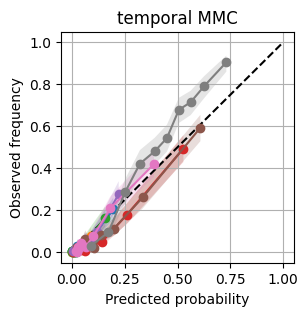

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

n_bins = 10

plt.figure(figsize=(3, 3))

# perfect calibration line
plt.plot([0, 1], [0, 1], "--", color="black", label="Perfect calibration")

for col in probs_retro.columns:
    df = pd.DataFrame({
        "y_prob": probs_pros[col],
        "y_true": Ypros[col]
    }).dropna()

    # Quantile-based bins
    df["bin"] = pd.qcut(df["y_prob"], q=n_bins, duplicates="drop")

    cal = (
        df.groupby("bin", observed=False)
          .agg(
              mean_pred=("y_prob", "mean"),
              obs_rate=("y_true", "mean"),
              n=("y_true", "size"),
              events=("y_true", "sum")
          )
          .dropna()
          .reset_index(drop=True)
    )

    # Wilson 95% CI for observed event rate in each bin
    ci_low, ci_upp = proportion_confint(
        count=cal["events"],
        nobs=cal["n"],
        alpha=0.05,
        method="wilson"
    )

    cal["ci_low"] = ci_low
    cal["ci_upp"] = ci_upp

    # line
    plt.plot(
        cal["mean_pred"],
        cal["obs_rate"],
        marker="o",
        label=col
    )

    # ribbon
    plt.fill_between(
        cal["mean_pred"],
        cal["ci_low"],
        cal["ci_upp"],
        alpha=0.2
    )

plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("temporal MMC")
# plt.legend()
plt.grid(True)
plt.show()


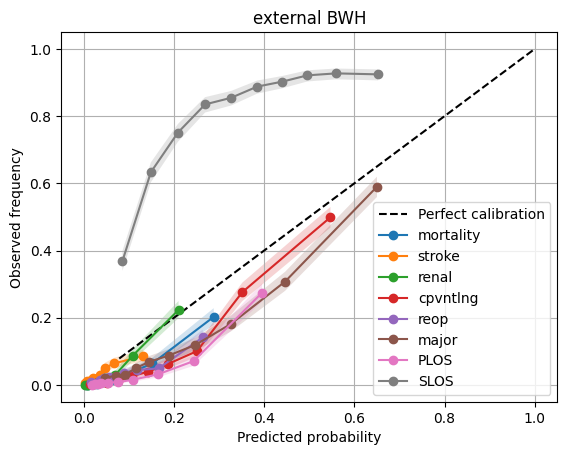

In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

n_bins = 10

# plt.figure(figsize=(3, 3))


# perfect calibration line
plt.plot([0, 1], [0, 1], "--", color="black", label="Perfect calibration")

for col in probs_retro.columns:
    df = pd.DataFrame({
        "y_prob": probs_bwh[col],
        "y_true": Y_bwh[col]
    }).dropna()

    # Quantile-based bins
    df["bin"] = pd.qcut(df["y_prob"], q=n_bins, duplicates="drop")

    cal = (
        df.groupby("bin", observed=False)
          .agg(
              mean_pred=("y_prob", "mean"),
              obs_rate=("y_true", "mean"),
              n=("y_true", "size"),
              events=("y_true", "sum")
          )
          .dropna()
          .reset_index(drop=True)
    )

    # Wilson 95% CI for observed event rate in each bin
    ci_low, ci_upp = proportion_confint(
        count=cal["events"],
        nobs=cal["n"],
        alpha=0.05,
        method="wilson"
    )

    cal["ci_low"] = ci_low
    cal["ci_upp"] = ci_upp

    # line
    plt.plot(
        cal["mean_pred"],
        cal["obs_rate"],
        marker="o",
        label=col
    )

    # ribbon
    plt.fill_between(
        cal["mean_pred"],
        cal["ci_low"],
        cal["ci_upp"],
        alpha=0.2
    )

plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("external BWH")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
df = pd.concat([Y_bwh.add_prefix("y_"),probs_bwh.add_prefix("p_")], axis=1)

In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import brier_score_loss
from sklearn.linear_model import LogisticRegression

def sigmoid_calibration_external_subset(
    y_true,
    y_prob,
    test_size=0.7,
    random_state=42
):
    """
    Fit sigmoid calibration on a subset of the external cohort,
    then evaluate Brier score on the remaining held-out subset.

    Parameters
    ----------
    y_true : array-like
        True binary labels (0/1)
    y_prob : array-like
        Original predicted probabilities from the trained model
    test_size : float
        Fraction of external cohort reserved for held-out evaluation
    random_state : int
        Random seed for reproducibility

    Returns
    -------
    results : dict
        Dictionary containing:
        - brier_before
        - brier_after
        - y_test
        - p_test_original
        - p_test_calibrated
        - calibration_model
    """

    # assemble and clean
    df = pd.DataFrame({
        "y_true": y_true,
        "y_prob": y_prob
    }).dropna()

    # split external cohort:
    # calibration subset + held-out evaluation subset
    calib_df, test_df = train_test_split(
        df,
        test_size=test_size,
        random_state=random_state,
        stratify=df["y_true"]
    )

    # Platt scaling / sigmoid calibration:
    # logistic regression on the model probability (better to use logit transform)
    eps = 1e-6
    p_calib = np.clip(calib_df["y_prob"].values, eps, 1 - eps)
    y_calib = calib_df["y_true"].values

    # logit transform of original probabilities
    x_calib = np.log(p_calib / (1 - p_calib)).reshape(-1, 1)

    calib_model = LogisticRegression(penalty=None, solver="lbfgs")
    calib_model.fit(x_calib, y_calib)

    # apply to held-out external subset
    p_test_original = np.clip(test_df["y_prob"].values, eps, 1 - eps)
    y_test = test_df["y_true"].values
    x_test = np.log(p_test_original / (1 - p_test_original)).reshape(-1, 1)

    p_test_calibrated = calib_model.predict_proba(x_test)[:, 1]

    # Brier score before and after calibration
    brier_before = brier_score_loss(y_test, p_test_original)
    brier_after = brier_score_loss(y_test, p_test_calibrated)

    results = {
        "brier_before": brier_before,
        "brier_after": brier_after,
        "y_test": y_test,
        "p_test_original": p_test_original,
        "p_test_calibrated": p_test_calibrated,
        "calibration_model": calib_model,
        "n_calibration": len(calib_df),
        "n_test": len(test_df)
    }

    return results

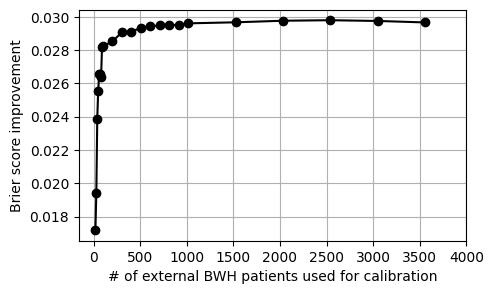

In [124]:
# Example:
# y_ext = external cohort true labels
# p_ext = external cohort predicted probabilities from your original model
res_test_size = dict()
for test_size in [0.65,0.7,0.75,0.8,0.85,0.9,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,0.991,0.992,0.993,0.994,0.995,0.996,0.997,0.998]:
    res_test_size[test_size] = dict()
    for col in Y_bwh.columns:
        res = sigmoid_calibration_external_subset(
            y_true=Y_bwh[col],
            y_prob=probs_bwh[col],
            test_size=test_size,   # 30% for calibration, 70% for evaluation
            random_state=42
        )
        res_test_size[test_size][col] = res
        
# how # of patients calibrated on affects Brier score improvement on held-out external subset
import matplotlib.pyplot as plt
test_sizes = []
brier_improvements = []
brier_after = []
for test_size, res_dict in res_test_size.items():
    deltabrier = np.array([])
    brierafter = np.array([])
    for col, res in res_dict.items():
        deltabrier = np.append(deltabrier, res["brier_before"] - res["brier_after"])
        brierafter = np.append(brierafter, res["brier_after"])
    
    test_sizes.append(res["n_calibration"])
    brier_improvements.append(np.mean(deltabrier))
    brier_after.append(np.mean(brierafter))

plt.figure(figsize=(5,3))

plt.plot(test_sizes, brier_improvements,'ko-')
plt.xlabel("# of external BWH patients used for calibration")
plt.ylabel("Brier score improvement")
plt.xticks(np.arange(0, max(test_sizes)+500, 500))
plt.grid()
plt.show()

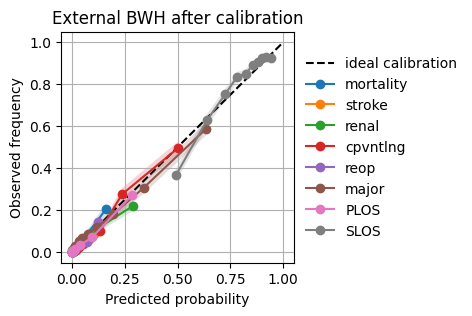

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

n_bins = 10

plt.figure(figsize=(3, 3))

# perfect calibration line
plt.plot([0, 1], [0, 1], "--", color="black", label="ideal calibration")

colplot = ['mortality','stroke','renal','prolonged vent','reoperation','major','PLOS','SLOS']
idx = 0
for col in probs_bwh.columns:
    df = pd.DataFrame({
        "y_prob": res_test_size[0.95][col]['p_test_calibrated'],
        "y_true": res_test_size[0.95][col]['y_test']
    }).dropna()

    # Quantile-based bins
    df["bin"] = pd.qcut(df["y_prob"], q=n_bins, duplicates="drop")

    cal = (
        df.groupby("bin", observed=False)
          .agg(
              mean_pred=("y_prob", "mean"),
              obs_rate=("y_true", "mean"),
              n=("y_true", "size"),
              events=("y_true", "sum")
          )
          .dropna()
          .reset_index(drop=True)
    )

    # Wilson 95% CI for observed event rate in each bin
    ci_low, ci_upp = proportion_confint(
        count=cal["events"],
        nobs=cal["n"],
        alpha=0.05,
        method="wilson"
    )

    cal["ci_low"] = ci_low
    cal["ci_upp"] = ci_upp

    # line
    plt.plot(
        cal["mean_pred"],
        cal["obs_rate"],
        marker="o",
        label=col#colplot[idx]
    )
    idx+=1

    # ribbon
    plt.fill_between(
        cal["mean_pred"],
        cal["ci_low"],
        cal["ci_upp"],
        alpha=0.2
    )

plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("External BWH after calibration",fontsize=12)
plt.legend()
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5),frameon=False)
plt.grid(True)
plt.show()
